# Package D — Data quality, correlation and regression

**Source dataset:** `team2_waste_data/processed/panel_country_year.csv` from the updated group repository. This notebook analyses the committed joined panel; it does not recreate or edit raw data.

**Research question:** How are population size and population growth associated with municipal waste collected, and how do population growth, year and world region relate to collected waste per person?

**Important terminology:** the UNSD series available in this repository is *municipal waste collected*, not total municipal waste generated. Results must be described using “collected”.

## 1. Load the joined panel and check its structure

The panel should contain one row per country/area and year. Country-year duplicates would make the panel key unreliable.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
import statsmodels.formula.api as smf

# Works when the notebook is run from package_D or from the repository root.
HERE = Path.cwd().resolve()
REPO_ROOT = HERE if (HERE / "team2_waste_data").exists() else HERE.parent
DATA_PATH = REPO_ROOT / "team2_waste_data" / "processed" / "panel_country_year.csv"
OUTPUT = REPO_ROOT / "package_D" / "outputs"
FIGURES = OUTPUT / "figures"
OUTPUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Years:", df.Year.min(), "to", df.Year.max())
print("Countries/areas:", df.CountryID.nunique())
print("Duplicate country-year keys:", df.duplicated(["CountryID", "Year"]).sum())
df.head()

Shape: (2532, 14)
Years: 2001 to 2024
Countries/areas: 142
Duplicate country-year keys: 0


,CountryID,ISO3,Country,SubRegion,Region,Year,Source_Collected,Source_Recycled,Waste_Collected_1000t,Recycled_Pct,Population_1000,Growth_Rate_Pct,Pop_Density_per_km2,Waste_kg_per_capita
0,8,ALB,Albania,Southern Europe,Europe,2001,E,E,NaN,8.352477,3147.943,-0.574989,114.897,NaN
1,8,ALB,Albania,Southern Europe,Europe,2002,E,E,NaN,9.102876,3134.092,-0.440002,114.391,NaN
2,8,ALB,Albania,Southern Europe,Europe,2003,E,E,NaN,10.506023,3118.088,-0.510642,113.807,NaN
3,8,ALB,Albania,Southern Europe,Europe,2004,E,E,NaN,13.316704,3098.657,-0.623170,113.098,NaN
4,8,ALB,Albania,Southern Europe,Europe,2005,E,E,NaN,15.661250,3076.159,-0.726056,112.277,NaN


## 2. Data coverage and modelling period

The assignment asks which years have sufficient waste data. To make the choice reproducible, this notebook selects the **longest consecutive run of years with at least 89 country/area observations for municipal waste collected**. In the supplied panel this is **2007–2021**, with 89–105 reporting countries/areas each year. Coverage drops to 71 in 2022, 65 in 2023 and zero in 2024. The threshold is a transparent coverage rule, not a claim that the selected years are perfectly representative.

,Year,panel_rows,countries,waste_n,recycling_n
0,2001,85,85,68,48
1,2002,90,90,72,51
2,2003,91,91,72,51
3,2004,101,101,82,50
4,2005,109,109,87,56
5,2006,107,107,86,58
6,2007,109,109,89,57
7,2008,113,113,91,65
8,2009,116,116,96,65
9,2010,119,119,98,68


Selected window: 2007-2021


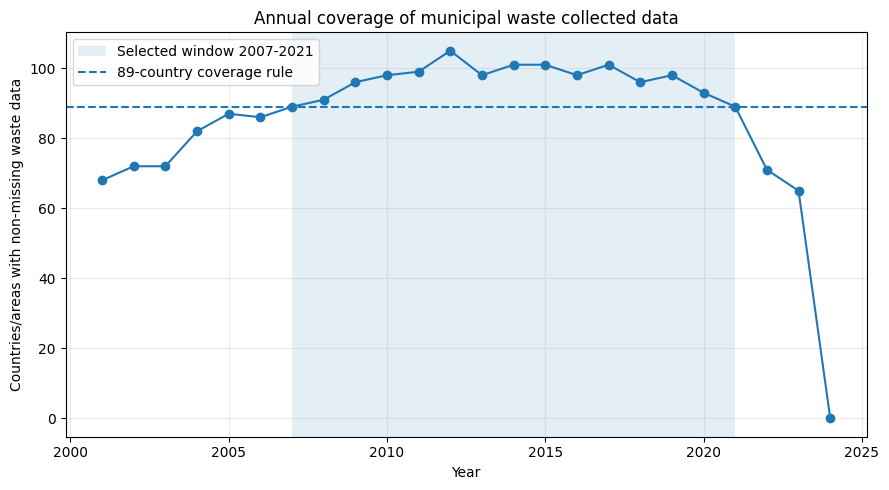

In [2]:
coverage = df.groupby("Year").agg(
    panel_rows=("CountryID", "size"),
    countries=("CountryID", "nunique"),
    waste_n=("Waste_Collected_1000t", "count"),
    recycling_n=("Recycled_Pct", "count")
).reset_index()
coverage.to_csv(OUTPUT / "annual_data_coverage_2001_2024.csv", index=False)
display(coverage)
qualified = coverage.loc[coverage.waste_n >= 89, "Year"].tolist()
runs, run = [], []
for year in qualified:
    if not run or year == run[-1] + 1:
        run.append(year)
    else:
        runs.append(run); run = [year]
if run: runs.append(run)
selected_run = max(runs, key=len)
START, END = selected_run[0], selected_run[-1]
print(f"Selected window: {START}-{END}")
assert (START, END) == (2007, 2021)
period = df[df.Year.between(START, END)].copy()
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(coverage.Year, coverage.waste_n, marker="o")
ax.axvspan(START, END, alpha=.12, label=f"Selected window {START}-{END}")
ax.axhline(89, linestyle="--", label="89-country coverage rule")
ax.set(title="Annual coverage of municipal waste collected data", xlabel="Year", ylabel="Countries/areas with non-missing waste data")
ax.legend(); ax.grid(alpha=.25); fig.tight_layout()
fig.savefig(FIGURES / "annual_waste_coverage.png", dpi=180)
plt.show()

## 3. Data quality and missingness

Check missing values, duplicate keys, impossible values and distributions. Population and growth are present in every panel row, but waste and recycling coverage is incomplete. In the full panel, waste collected is missing in 18.8% of rows and recycling percentage in 41.3%. The 2024 panel rows have no waste-collected observations.

In [3]:
quality = pd.DataFrame({
    "missing_n": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(1)
})
display(quality)
print("Negative waste values:", (df.Waste_Collected_1000t < 0).sum())
invalid_recycling = df[(df.Recycled_Pct < 0) | (df.Recycled_Pct > 100)][["Country", "Year", "Recycled_Pct"]]
print("Recycling values outside 0–100%:", len(invalid_recycling))
display(invalid_recycling)
print("Waste per capita > 1,000 kg/person/year:", (period.Waste_kg_per_capita > 1000).sum())
print("Selected-period rows:", len(period))
print("Selected-period waste values:", period.Waste_Collected_1000t.notna().sum())
print("Selected-period countries with waste data:", period.loc[period.Waste_Collected_1000t.notna(), "CountryID"].nunique())
invalid_recycling.to_csv(OUTPUT / "recycling_values_outside_0_100.csv", index=False)

,missing_n,missing_pct
CountryID,0,0.0
ISO3,0,0.0
Country,0,0.0
SubRegion,0,0.0
Region,0,0.0
Year,0,0.0
Source_Collected,44,1.7
Source_Recycled,405,16.0
Waste_Collected_1000t,476,18.8
Recycled_Pct,1045,41.3


Negative waste values: 0
Recycling values outside 0–100%: 5


,Country,Year,Recycled_Pct
2296,United Arab Emirates,2018,112.006489
2297,United Arab Emirates,2019,128.662783
2298,United Arab Emirates,2020,177.657639
2300,United Arab Emirates,2022,147.664703
2301,United Arab Emirates,2023,177.657639


Waste per capita > 1,000 kg/person/year: 113
Selected-period rows: 1719
Selected-period waste values: 1453
Selected-period countries with waste data: 132


## 4. Summary statistics, histograms and outliers

The distributions are right-skewed, especially for total waste collected and population. Use the IQR rule to *flag* unusual observations for review, not to delete them automatically. Large countries naturally have high total waste, and small countries can have high per-capita values.

,count,mean,std,min,25%,50%,75%,max
Waste_Collected_1000t,1453.0,11548.019694,36871.105681,0.690000,461.000000,2559.015100,6079.000000,5.891680e+05
Population_1000,1719.0,38213.077494,152620.218148,4.479000,1100.198500,6907.812000,24179.618000,1.426437e+06
Growth_Rate_Pct,1719.0,0.893227,1.539749,-3.793153,0.015875,0.707812,1.520777,1.806585e+01
Waste_kg_per_capita,1453.0,507.704823,499.159925,0.046574,282.126219,431.544751,592.480389,7.514587e+03
Recycled_Pct,1004.0,18.226982,16.691239,0.000000,3.906747,18.028907,26.808690,1.776576e+02


,n,Q1,Q3,lower_fence,upper_fence,flagged
Waste_Collected_1000t,1453.0,461.000000,6079.000000,-7966.000000,14506.000000,220.0
Population_1000,1719.0,1100.198500,24179.618000,-33518.930750,58798.747250,201.0
Growth_Rate_Pct,1719.0,0.015875,1.520777,-2.241478,3.778131,64.0
Waste_kg_per_capita,1453.0,282.126219,592.480389,-183.405036,1058.011644,104.0
Recycled_Pct,1004.0,3.906747,26.808690,-30.446168,61.161605,10.0


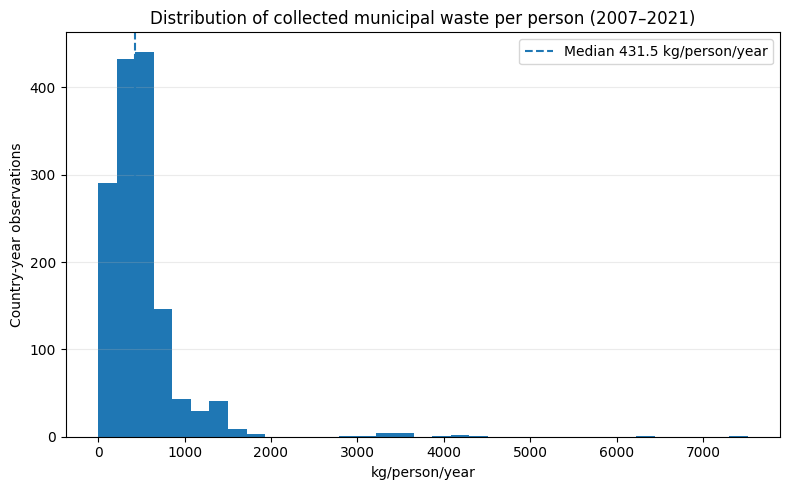

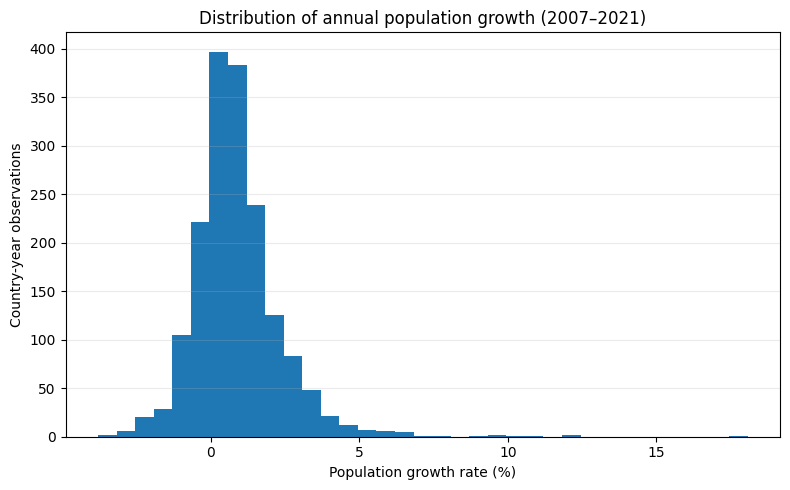

In [4]:
variables = ["Waste_Collected_1000t", "Population_1000", "Growth_Rate_Pct", "Waste_kg_per_capita", "Recycled_Pct"]
summary = period[variables].describe().T
display(summary)
summary.to_csv(OUTPUT / "descriptive_statistics_2007_2021.csv")

def iqr_flag(series):
    s = series.dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3-q1
    lower, upper = q1-1.5*iqr, q3+1.5*iqr
    return {"n": len(s), "Q1": q1, "Q3": q3, "lower_fence": lower, "upper_fence": upper, "flagged": int(((s<lower)|(s>upper)).sum())}
iqr_table = pd.DataFrame({name: iqr_flag(period[name]) for name in variables}).T
display(iqr_table)

fig, ax = plt.subplots(figsize=(8, 5)); ax.hist(period.Waste_kg_per_capita.dropna(), bins=35)
ax.axvline(period.Waste_kg_per_capita.median(), linestyle="--", label=f"Median {period.Waste_kg_per_capita.median():.1f} kg/person/year")
ax.set(title="Distribution of collected municipal waste per person (2007–2021)", xlabel="kg/person/year", ylabel="Country-year observations"); ax.legend(); ax.grid(axis="y", alpha=.25); fig.tight_layout(); fig.savefig(FIGURES/"waste_per_capita_distribution.png", dpi=180); plt.show()

fig, ax = plt.subplots(figsize=(8, 5)); ax.hist(period.Growth_Rate_Pct.dropna(), bins=35)
ax.set(title="Distribution of annual population growth (2007–2021)", xlabel="Population growth rate (%)", ylabel="Country-year observations"); ax.grid(axis="y", alpha=.25); fig.tight_layout(); fig.savefig(FIGURES/"population_growth_distribution.png", dpi=180); plt.show()

## 5. Correlation analysis

Use Pearson correlation for linear association and Spearman correlation for monotonic association that is less sensitive to skewed distributions. Both are calculated on the same waste-complete country-year sample.

In [5]:
waste_sample = period.dropna(subset=["Waste_Collected_1000t", "Population_1000"]).copy()
correlations = []
for label, x, y in [
    ("Population vs collected waste", waste_sample.Population_1000, waste_sample.Waste_Collected_1000t),
    ("Population growth vs collected waste", waste_sample.Growth_Rate_Pct, waste_sample.Waste_Collected_1000t),
]:
    p = pearsonr(x, y); s = spearmanr(x, y)
    correlations.append({"Comparison": label, "N": len(x), "Pearson_r": p.statistic, "Pearson_p": p.pvalue, "Spearman_rho": s.statistic, "Spearman_p": s.pvalue})
corr_df = pd.DataFrame(correlations)
display(corr_df)
corr_df.to_csv(OUTPUT / "correlations_2007_2021.csv", index=False)

,Comparison,N,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,Population vs collected waste,1453,0.594353,1.711084e-139,0.848113,0.00000
1,Population growth vs collected waste,1453,0.022714,3.869389e-01,-0.012235,0.64123


## 6. Simple linear regression: total waste collected vs population

Model: `Waste_Collected_1000t ~ Population_1000`. Both measures are expressed in thousands (thousand tonnes and thousand persons). Standard errors are clustered by country/area because each country contributes repeated annual observations.

                              OLS Regression Results                             
Dep. Variable:     Waste_Collected_1000t   R-squared:                       0.353
Model:                               OLS   Adj. R-squared:                  0.353
Method:                    Least Squares   F-statistic:                     21.84
Date:                   Fri, 27 Nov 2026   Prob (F-statistic):           7.27e-06
Time:                           12:37:33   Log-Likelihood:                -17023.
No. Observations:                   1453   AIC:                         3.405e+04
Df Residuals:                       1451   BIC:                         3.406e+04
Df Model:                              1                                         
Covariance Type:                 cluster                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept   

,coefficient,clustered_se,p_value,ci_low,ci_high
Intercept,6028.299766,1548.860703,0.000099,2992.588571,9064.010960
Population_1000,0.132877,0.028434,0.000003,0.077147,0.188606


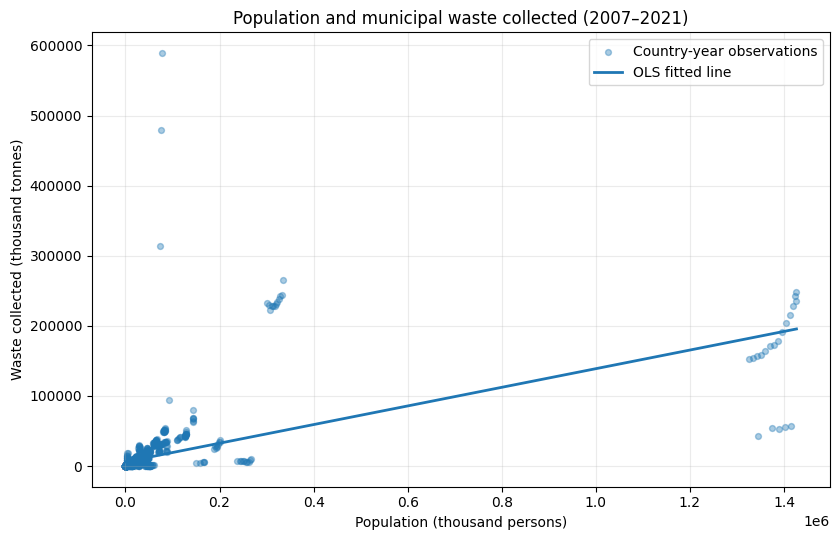

R-squared: 0.353
Interpretation: +1,000 residents is associated with about 132.9 tonnes more collected waste in this pooled sample.


In [6]:
simple = smf.ols("Waste_Collected_1000t ~ Population_1000", data=waste_sample).fit(
    cov_type="cluster", cov_kwds={"groups": waste_sample.CountryID}
)
print(simple.summary())
simple_table = pd.DataFrame({"coefficient": simple.params, "clustered_se": simple.bse, "p_value": simple.pvalues})
simple_table["ci_low"] = simple.conf_int()[0]
simple_table["ci_high"] = simple.conf_int()[1]
display(simple_table)
simple_table.to_csv(OUTPUT / "simple_regression_coefficients.csv")

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(waste_sample.Population_1000, waste_sample.Waste_Collected_1000t, alpha=.38, s=18, label="Country-year observations")
xline = np.linspace(waste_sample.Population_1000.min(), waste_sample.Population_1000.max(), 200)
ax.plot(xline, simple.params["Intercept"] + simple.params["Population_1000"]*xline, linewidth=2, label="OLS fitted line")
ax.set(title="Population and municipal waste collected (2007–2021)", xlabel="Population (thousand persons)", ylabel="Waste collected (thousand tonnes)")
ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); fig.savefig(FIGURES/"population_vs_waste.png", dpi=180); plt.show()
print(f"R-squared: {simple.rsquared:.3f}")
print(f"Interpretation: +1,000 residents is associated with about {simple.params['Population_1000']*1000:.1f} tonnes more collected waste in this pooled sample.")

## 7. Multiple regression: waste collected per person

Model: `Waste_kg_per_capita ~ Growth_Rate_Pct + Year_since_2007 + C(Region)`. Africa is the reference region (alphabetical baseline). The growth coefficient is interpreted per one percentage-point increase in population growth, holding year and region constant. Country-clustered standard errors account for repeated country-year rows.

In [7]:
multiple_sample = period.dropna(subset=["Waste_kg_per_capita", "Growth_Rate_Pct", "Year", "Region", "CountryID"]).copy()
multiple_sample["Year_since_2007"] = multiple_sample.Year - START
multiple = smf.ols("Waste_kg_per_capita ~ Growth_Rate_Pct + Year_since_2007 + C(Region)", data=multiple_sample).fit(
    cov_type="cluster", cov_kwds={"groups": multiple_sample.CountryID}
)
print(multiple.summary())
multiple_table = pd.DataFrame({"coefficient": multiple.params, "clustered_se": multiple.bse, "p_value": multiple.pvalues})
multiple_table["ci_low"] = multiple.conf_int()[0]
multiple_table["ci_high"] = multiple.conf_int()[1]
display(multiple_table)
multiple_table.to_csv(OUTPUT / "multiple_regression_coefficients.csv")
print(f"N={int(multiple.nobs)}, countries={multiple_sample.CountryID.nunique()}, R-squared={multiple.rsquared:.3f}, adjusted R-squared={multiple.rsquared_adj:.3f}")

                             OLS Regression Results                            
Dep. Variable:     Waste_kg_per_capita   R-squared:                       0.110
Model:                             OLS   Adj. R-squared:                  0.107
Method:                  Least Squares   F-statistic:                     2.667
Date:                 Fri, 27 Nov 2026   Prob (F-statistic):             0.0179
Time:                         12:37:33   Log-Likelihood:                -11004.
No. Observations:                 1453   AIC:                         2.202e+04
Df Residuals:                     1446   BIC:                         2.206e+04
Df Model:                            6                                         
Covariance Type:               cluster                                         
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept           

,coefficient,clustered_se,p_value,ci_low,ci_high
Intercept,66.651099,186.122243,0.720266,-298.141795,431.443993
C(Region)[T.Americas],331.412548,192.032522,0.084381,-44.964279,707.789376
C(Region)[T.Asia],259.902546,207.916718,0.211288,-147.606733,667.411825
C(Region)[T.Europe],403.507236,182.098698,0.026700,46.600346,760.414125
C(Region)[T.Oceania],199.547580,185.817859,0.282873,-164.648731,563.743892
Growth_Rate_Pct,122.833730,49.641552,0.013346,25.538076,220.129383
Year_since_2007,3.811162,2.420777,0.115405,-0.933473,8.555798


N=1453, countries=132, R-squared=0.110, adjusted R-squared=0.107


## 8. Conclusions and limitations

- Population size has a positive association with total municipal waste collected in this pooled country-year sample (Pearson r ≈ 0.594; simple-model R² ≈ 0.353).
- Population growth has almost no simple linear/monotonic association with total collected waste in this sample (Pearson r ≈ 0.023; p ≈ 0.387).
- In the multiple model, the population-growth coefficient for waste collected per person is positive (about 122.8 kg/person/year for each percentage-point higher growth rate; p ≈ 0.013), while the year coefficient is not statistically distinguishable from zero at the 5% level (p ≈ 0.115). Interpret cautiously; the model R² is about 0.110.
- The dataset is unbalanced and contains unusual per-capita observations. IQR flags are not automatically errors, and no outliers were deleted.
- The UNSD measure is waste collected, not all waste generated. Waste per person divides by total population, not only the population served by collection.
- These are observational associations, not causal effects. Income, urbanisation, consumption, collection coverage, policy and infrastructure are omitted.

The notebook is designed to run top-to-bottom from the supplied repository. Outputs are saved under `package_D/outputs/`.